# 05 — Exponential- und Logarithmusfunktionen

**Voraussetzungen:** [01_Funktionsbegriff](01_Funktionsbegriff_Grundlagen.ipynb), [00_Grundlagen/04_Exponenten_Logarithmen](../00_Grundlagen/04_Exponenten_Logarithmen.ipynb)

---

## Lernziele

Nach diesem Notebook kannst du:
- Die **Exponentialfunktion** $a^x$ und insbesondere $e^x$ graphisch und algebraisch beschreiben
- Die **Eulersche Zahl** $e$ motivieren und einordnen
- Die **Logarithmusfunktion** als Umkehrung der Exponentialfunktion verstehen
- **Logarithmengesetze** sicher anwenden
- Exponential- und Logarithmusgleichungen lösen

### 1. Exponentialfunktionen

Eine **Exponentialfunktion** hat die Variable im Exponenten:

$$f(x) = a^x \qquad (a > 0, \; a \ne 1)$$

| Eigenschaft | Wert |
|-------------|------|
| Definitionsbereich | $D = \mathbb{R}$ |
| Wertebereich | $W = (0, \infty)$ — immer positiv |
| y-Achsenabschnitt | $f(0) = a^0 = 1$ (für alle $a$) |
| Monotonie | Steigend für $a > 1$, fallend für $0 < a < 1$ |
| Asymptote | $y = 0$ (horizontale Asymptote für $x \to -\infty$ bzw. $+\infty$) |

**Vergleich verschiedener Basen:**

| Basis | Verhalten |
|-------|-----------|
| $a > 1$ | Wachstum — Graph steigt nach rechts |
| $a = 1$ | Konstant: $f(x) = 1$ (kein Exponentialverhalten) |
| $0 < a < 1$ | Zerfall — Graph fällt nach rechts |

Zwischen den Basen besteht der Zusammenhang: $a^x = \left(\frac{1}{a}\right)^{-x}$. Ein Zerfall mit Basis $a$ ist also ein Wachstum mit Basis $\frac{1}{a}$, gespiegelt an der y-Achse.

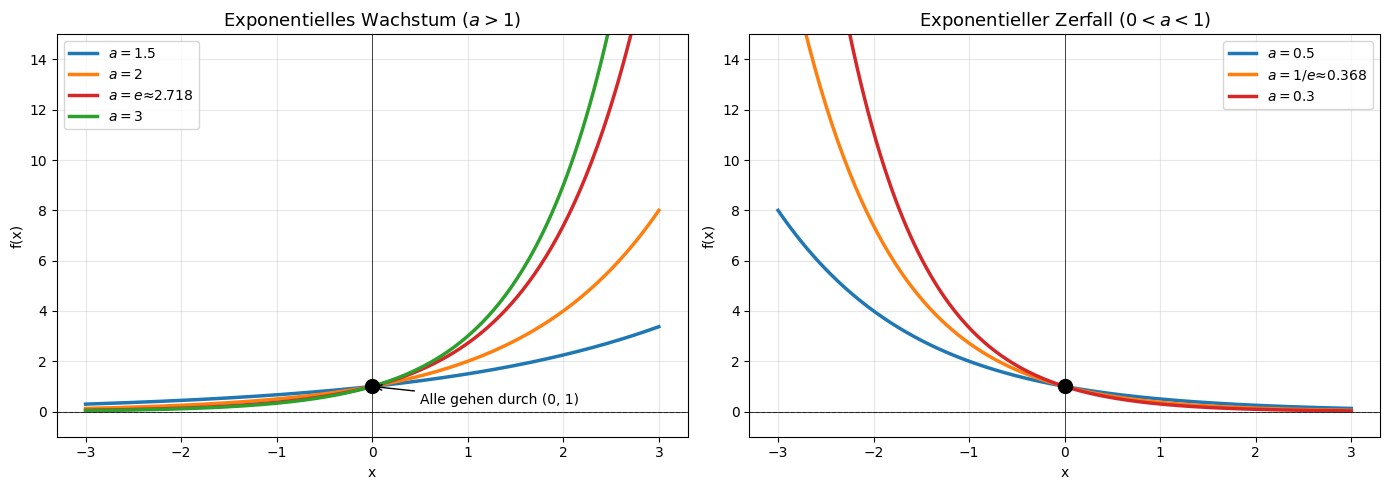

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- Exponentialfunktionen verschiedener Basen ---

def visualisiere_exponentialfunktionen():
    """Vergleicht Exponentialfunktionen mit verschiedenen Basen."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    x = np.linspace(-3, 3, 300)

    # --- Links: Wachstum (a > 1) ---
    ax = axes[0]
    basen = [1.5, 2, np.e, 3]
    labels = ['1.5', '2', 'e ≈ 2.718', '3']
    farben = ['#1f77b4', '#ff7f0e', '#d62728', '#2ca02c']
    for a, label, farbe in zip(basen, labels, farben):
        ax.plot(x, a**x, color=farbe, linewidth=2.5, label=f"$a = {label}$")
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.scatter(0, 1, color='black', s=100, zorder=5)
    ax.annotate("Alle gehen durch (0, 1)", xy=(0, 1), xytext=(0.5, 0.3),
                fontsize=10, arrowprops=dict(arrowstyle='->', color='black'))
    ax.set_title("Exponentielles Wachstum ($a > 1$)", fontsize=13)
    ax.legend(fontsize=10)
    ax.set_ylim(-1, 15)

    # --- Rechts: Zerfall (0 < a < 1) ---
    ax = axes[1]
    basen_z = [0.5, 1/np.e, 0.3]
    labels_z = ['0.5', '1/e ≈ 0.368', '0.3']
    for a, label, farbe in zip(basen_z, labels_z, farben[:3]):
        ax.plot(x, a**x, color=farbe, linewidth=2.5, label=f"$a = {label}$")
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.scatter(0, 1, color='black', s=100, zorder=5)
    ax.set_title("Exponentieller Zerfall ($0 < a < 1$)", fontsize=13)
    ax.legend(fontsize=10)
    ax.set_ylim(-1, 15)

    for ax in axes:
        ax.grid(True, alpha=0.3)
        ax.axhline(0, color='black', linewidth=0.5)
        ax.axvline(0, color='black', linewidth=0.5)
        ax.set_xlabel("x")
        ax.set_ylabel("f(x)")

    plt.tight_layout()
    plt.show()

visualisiere_exponentialfunktionen()

### 2. Die Eulersche Zahl $e$

Die Zahl $e \approx 2{,}71828\ldots$ ist die wichtigste Basis für Exponentialfunktionen. Sie entsteht aus der Frage:

> Welche Exponentialfunktion hat bei $x = 0$ die Steigung genau 1?

Es gilt: $\dfrac{d}{dx}\, e^x = e^x$ — die e-Funktion ist ihre eigene Ableitung.

**Definition über den Grenzwert:**

$$e = \lim_{n \to \infty} \left(1 + \frac{1}{n}\right)^n$$

**Motivation (Zinseszins):** Du legst 1 GE an mit 100% Jahreszins. Wie viel hast du nach einem Jahr, wenn $n$-mal pro Jahr verzinst wird?

| $n$ (Verzinsungen/Jahr) | $\left(1 + \frac{1}{n}\right)^n$ |
|--------------------------|----------------------------------|
| 1 (jährlich) | 2,000 |
| 12 (monatlich) | 2,613 |
| 365 (täglich) | 2,715 |
| $\to \infty$ (stetig) | $e \approx 2{,}71828$ |

---

### Umrechnung zwischen Basen

Jede Exponentialfunktion $a^x$ lässt sich mit Basis $e$ schreiben:

$$a^x = e^{x \cdot \ln(a)}$$

Das ist nützlich, weil man mit $e^x$ leichter differenzieren und integrieren kann.

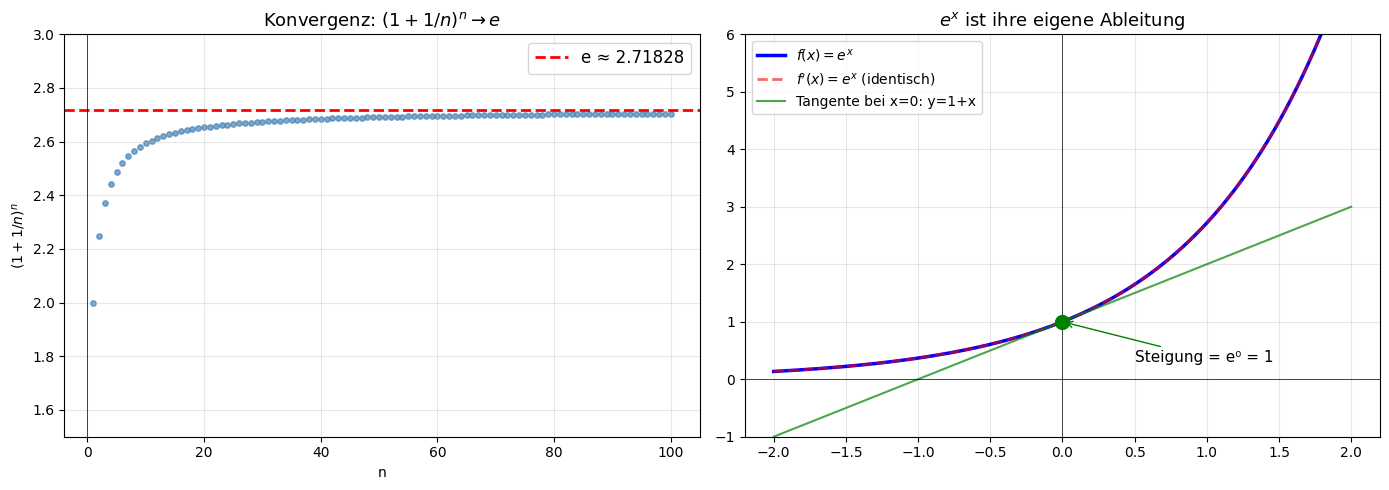

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# --- Konvergenz der Euler-Folge ---

def visualisiere_euler_konvergenz():
    """Zeigt die Konvergenz von (1 + 1/n)^n gegen e."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # --- Links: Konvergenz der Folge ---
    ax = axes[0]
    n_werte = np.arange(1, 101)
    folge = (1 + 1/n_werte)**n_werte
    ax.scatter(n_werte, folge, s=15, color='steelblue', alpha=0.7)
    ax.axhline(np.e, color='red', linestyle='--', linewidth=2, label=f"e ≈ {np.e:.5f}")
    ax.set_xlabel("n")
    ax.set_ylabel(r"$(1 + 1/n)^n$")
    ax.set_title(r"Konvergenz: $(1 + 1/n)^n \to e$", fontsize=13)
    ax.legend(fontsize=12)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(1.5, 3)

    # --- Rechts: e^x ist eigene Ableitung ---
    ax = axes[1]
    x = np.linspace(-2, 2, 300)
    ax.plot(x, np.exp(x), 'b-', linewidth=2.5, label=r"$f(x) = e^x$")
    ax.plot(x, np.exp(x), 'r--', linewidth=2, alpha=0.6, label=r"$f'(x) = e^x$ (identisch)")
    # Tangente bei x=0
    tangente = 1 + x  # e^0 + e^0 · (x-0) = 1 + x
    ax.plot(x, tangente, 'g-', linewidth=1.5, alpha=0.7, label="Tangente bei x=0: y=1+x")
    ax.scatter(0, 1, color='green', s=100, zorder=5)
    ax.annotate("Steigung = e⁰ = 1", xy=(0, 1), xytext=(0.5, 0.3),
                fontsize=11, arrowprops=dict(arrowstyle='->', color='green'))
    ax.set_title(r"$e^x$ ist ihre eigene Ableitung", fontsize=13)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(-1, 6)

    for ax in axes:
        ax.axhline(0, color='black', linewidth=0.5)
        ax.axvline(0, color='black', linewidth=0.5)

    plt.tight_layout()
    plt.show()

visualisiere_euler_konvergenz()

### 3. Die Logarithmusfunktion

Der **Logarithmus** ist die Umkehroperation des Potenzierens:

$$\log_a(y) = x \quad \Longleftrightarrow \quad a^x = y$$

Gelesen: „Der Logarithmus von $y$ zur Basis $a$ ist $x$" — also: *Welchen Exponent braucht man bei Basis $a$, um $y$ zu erhalten?*

| Notation | Basis | Üblich in |
|----------|-------|-----------|
| $\ln(x) = \log_e(x)$ | $e$ | Mathematik, Physik |
| $\log(x) = \log_{10}(x)$ | 10 | Taschenrechner, Ingenieurwesen |
| $\log_2(x)$ | 2 | Informatik |

---

### Eigenschaften der Logarithmusfunktion

| Eigenschaft | Wert |
|-------------|------|
| Definitionsbereich | $D = (0, \infty)$ — nur positive Argumente |
| Wertebereich | $W = \mathbb{R}$ |
| Nullstelle | $\log_a(1) = 0$ |
| Fixpunkt | $\log_a(a) = 1$ |
| Monotonie | Streng steigend (für $a > 1$) |
| Asymptote | $x = 0$ (vertikale Asymptote) |

**Umkehrbeziehung:**
$$a^{\log_a(x)} = x \qquad \text{und} \qquad \log_a(a^x) = x$$

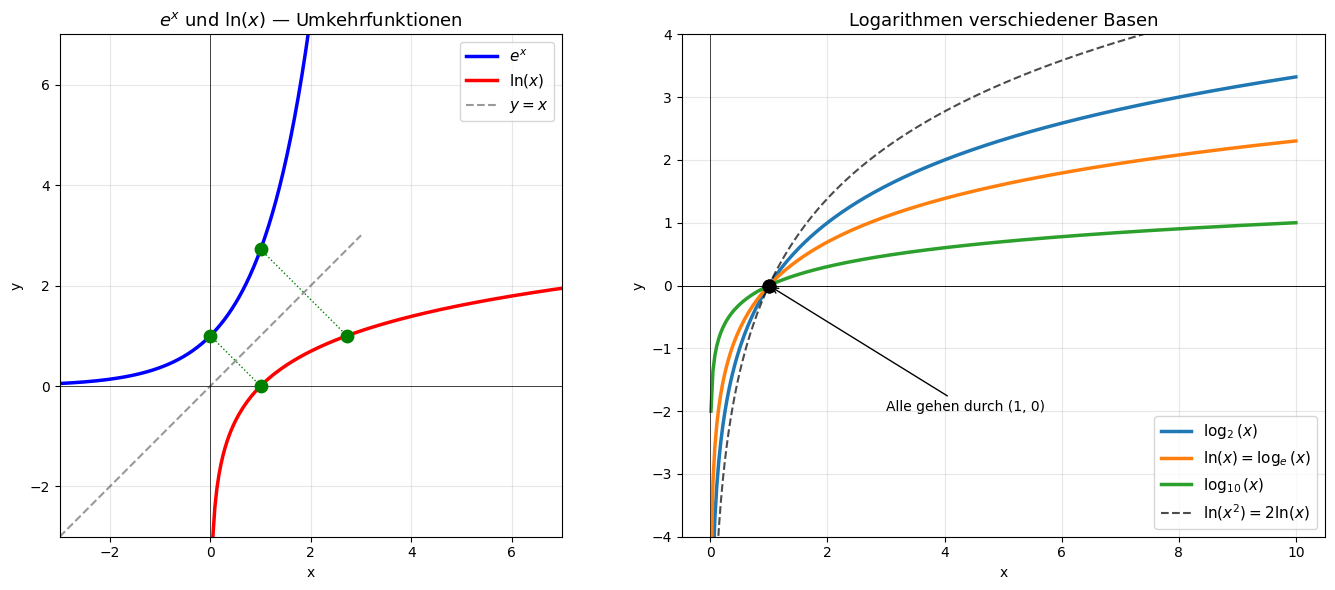

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# --- Exponentialfunktion und Logarithmus als Umkehrung ---

def visualisiere_exp_log_umkehrung():
    """Zeigt e^x und ln(x) als Spiegelung an y=x."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # --- Links: e^x und ln(x) ---
    ax = axes[0]
    x_exp = np.linspace(-3, 2.5, 300)
    x_log = np.linspace(0.01, 12, 300)
    diag = np.linspace(-3, 3, 100)

    ax.plot(x_exp, np.exp(x_exp), 'b-', linewidth=2.5, label=r"$e^x$")
    ax.plot(x_log, np.log(x_log), 'r-', linewidth=2.5, label=r"$\ln(x)$")
    ax.plot(diag, diag, 'k--', alpha=0.4, label=r"$y = x$")

    # Spiegelpunkte
    punkte = [(0, 1), (1, np.e)]
    for px, py in punkte:
        ax.scatter([px, py], [py, px], color='green', s=80, zorder=5)
        ax.plot([px, py], [py, px], 'g:', linewidth=1)

    ax.set_title(r"$e^x$ und $\ln(x)$ — Umkehrfunktionen", fontsize=13)
    ax.legend(fontsize=11)
    ax.set_xlim(-3, 7)
    ax.set_ylim(-3, 7)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)

    # --- Rechts: Logarithmen verschiedener Basen ---
    ax = axes[1]
    x = np.linspace(0.01, 10, 300)
    ax.plot(x, np.log2(x), linewidth=2.5, label=r"$\log_2(x)$")
    ax.plot(x, np.log(x), linewidth=2.5, label=r"$\ln(x) = \log_e(x)$")
    ax.plot(x, np.log10(x), linewidth=2.5, label=r"$\log_{10}(x)$")

    ax.plot(x, np.log(x**2), 'k--', linewidth=1.5, alpha=0.7, label=r"$\ln(x^2) = 2\ln(x)$")

    ax.scatter([1, 1, 1], [0, 0, 0], color='black', s=80, zorder=5)
    ax.annotate("Alle gehen durch (1, 0)", xy=(1, 0), xytext=(3, -2),
                fontsize=10, arrowprops=dict(arrowstyle='->', color='black'))
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_title("Logarithmen verschiedener Basen", fontsize=13)
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(-4, 4)

    for ax in axes:
        ax.axhline(0, color='black', linewidth=0.5)
        ax.axvline(0, color='black', linewidth=0.5)
        ax.set_xlabel("x")
        ax.set_ylabel("y")

    plt.tight_layout()
    plt.show()

visualisiere_exp_log_umkehrung()

### 4. Logarithmengesetze

Diese Regeln gelten für jeden Logarithmus mit Basis $a > 0, a \ne 1$:

| Gesetz | Formel | Entspricht |
|--------|--------|------------|
| **Produktregel** | $\log(u \cdot v) = \log(u) + \log(v)$ | „Multiplikation → Addition" |
| **Quotientenregel** | $\log\left(\frac{u}{v}\right) = \log(u) - \log(v)$ | „Division → Subtraktion" |
| **Potenzregel** | $\log(u^k) = k \cdot \log(u)$ | „Exponent → Faktor" |
| **Basiswechsel** | $\log_a(x) = \frac{\ln(x)}{\ln(a)}$ | Umrechnung zwischen Basen |

**Spezielle Werte:**

$$\log_a(1) = 0 \qquad \log_a(a) = 1 \qquad \ln(e) = 1$$

---

### Exponential- und Logarithmusgleichungen lösen

| Gleichungstyp | Strategie | Beispiel |
|---------------|-----------|----------|
| $a^x = b$ | Logarithmieren: $x = \frac{\ln b}{\ln a}$ | $2^x = 8 \Rightarrow x = 3$ |
| $\log_a(x) = b$ | Potenzieren: $x = a^b$ | $\log_2(x) = 5 \Rightarrow x = 32$ |
| $e^{f(x)} = g(x)$ | $f(x) = \ln(g(x))$ | $e^{2x} = 7 \Rightarrow x = \frac{\ln 7}{2}$ |

In [12]:
import sympy as sp

x = sp.Symbol('x')

print("=== Logarithmengesetze mit SymPy ===")
print()

# Produktregel
ln_mult = sp.log(2*3).evalf()
ln_summe = sp.log(2) + sp.log(3).evalf()
print(f"ln(2·3) = {float(ln_mult):.5f}")
print(f"ln(2) + ln(3) = {float(ln_summe):.5f}")
print()

# Potenzregel
ln_potenz = sp.log(2**5).evalf()
ln_faktor = (5*sp.log(2)).evalf()
print(f"ln(2⁵) = {float(ln_potenz):.5f}")
print(f"5·ln(2) = {float(ln_faktor):.5f}")

# Gleichungen lösen: 2^x = 10, e^(2x) = 7, ln(x) = 3
gl_expx = sp.solve(2**x - 10, x)[0].evalf()
gl_expx2 = sp.solve(sp.exp(2*x) - 7, x)[0]
gl_expx2 = sp.re(gl_expx2).evalf()  # Extract real part
gl_ln = sp.solve(sp.log(x) - 3, x)[0].evalf()

print("=== Gleichungen lösen ===")
print(f"2^x = 10  → x = {float(gl_expx):.5f}")
print(f"e^(2x) = 7 → x = {float(gl_expx2):.5f}")
print(f"ln(x) = 3  → x = {float(gl_ln):.5f}")


=== Logarithmengesetze mit SymPy ===

ln(2·3) = 1.79176
ln(2) + ln(3) = 1.79176

ln(2⁵) = 3.46574
5·ln(2) = 3.46574
=== Gleichungen lösen ===
2^x = 10  → x = 3.32193
e^(2x) = 7 → x = 0.97296
ln(x) = 3  → x = 20.08554


---

## Verständnis-Check

**Aufgabe 1:** Vereinfache: $\ln(e^3) + \ln\left(\frac{1}{e}\right)$

**Aufgabe 2:** Löse nach $x$ auf: $5^{x+1} = 125$

**Aufgabe 3:** Schreibe $3^x$ in der Form $e^{kx}$. Welchen Wert hat $k$?

**Aufgabe 4:** Vereinfache: $\log_2(8) + \log_2(4) - \log_2(16)$

**Aufgabe 5:** Bestimme den Definitions- und Wertebereich von $f(x) = \ln(x - 2) + 1$.

### Lösungen

<details>
<summary>Lösung Aufgabe 1</summary>

$$\ln(e^3) + \ln\left(\frac{1}{e}\right) = 3 + \ln(e^{-1}) = 3 + (-1) = 2$$
</details>

<details>
<summary>Lösung Aufgabe 2</summary>

$125 = 5^3$, also $5^{x+1} = 5^3 \Rightarrow x + 1 = 3 \Rightarrow x = 2$.
</details>

<details>
<summary>Lösung Aufgabe 3</summary>

$$3^x = e^{x \ln 3}$$

Also $k = \ln 3 \approx 1{,}0986$.
</details>

<details>
<summary>Lösung Aufgabe 4</summary>

$$\log_2(8) + \log_2(4) - \log_2(16) = 3 + 2 - 4 = 1$$

Alternativ per Logarithmengesetze: $\log_2\left(\frac{8 \cdot 4}{16}\right) = \log_2(2) = 1$.
</details>

<details>
<summary>Lösung Aufgabe 5</summary>

Bedingung: $x - 2 > 0 \Rightarrow x > 2$, also $D = (2, \infty)$.

Da $\ln$ alle reellen Werte annimmt und $+1$ nur verschiebt: $W = \mathbb{R}$.
</details>

---

## Zusammenfassung

| Thema | Kernaussage |
|-------|-------------|
| **Exponentialfunktion** | $a^x$: Basis $a>1$ → Wachstum, $0<a<1$ → Zerfall |
| **Eulersche Zahl** | $e \approx 2{,}718$; $e^x$ ist ihre eigene Ableitung |
| **Logarithmus** | $\log_a(x)$: Umkehrung von $a^x$ |
| **Logarithmengesetze** | Produkt→Summe, Quotient→Differenz, Potenz→Faktor |
| **Basiswechsel** | $a^x = e^{x\ln a}$, $\log_a(x) = \frac{\ln x}{\ln a}$ |
| **Gleichungen** | Logarithmieren bzw. Potenzieren zum Auflösen |

> **Nächster Schritt:** Anwendung der Exponentialfunktion auf Wachstums- und Zerfallsprozesse → 06_Wachstum_Zerfall

---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Exponentialfunktion | Exponential function |
| Eulersche Zahl | Euler's number |
| Logarithmus | Logarithm |
| Natürlicher Logarithmus | Natural logarithm |
| Basiswechsel | Change of base |
| Umkehrfunktion | Inverse function |
| Asymptote | Asymptote |